In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving fake_job_postings.csv to fake_job_postings.csv


In [ ]:
import io

filename = next(iter(uploaded))

df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (17880, 18)


,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0


In [ ]:
# Display all column names
print("Dataset Columns:")
print(df.columns.tolist())

# Display number of rows and columns
print("\nDataset Shape:")
print(df.shape)

# Display first 5 job postings
print("\nFirst 5 Job Postings:")
display(df.head())

Dataset Columns:
['job_id', 'title', 'location', 'department', 'salary_range', 'company_profile', 'description', 'requirements', 'benefits', 'telecommuting', 'has_company_logo', 'has_questions', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'fraudulent']

Dataset Shape:
(17880, 18)

First 5 Job Postings:


,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0


In [ ]:
# Check missing values in each column
missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values[missing_values > 0].sort_values(ascending=False))

Missing Values:
salary_range           15012
department             11547
required_education      8105
benefits                7212
required_experience     7050
function                6455
industry                4903
employment_type         3471
company_profile         3308
requirements            2696
location                 346
description                1
dtype: int64


In [ ]:
if "fraudulent" in df.columns:
    print("Job Posting Classification:")
    print(df["fraudulent"].value_counts())

    print("\nPercentage:")
    print(df["fraudulent"].value_counts(normalize=True).mul(100).round(2))
else:
    print("The 'fraudulent' column was not found.")

Job Posting Classification:
fraudulent
0    17014
1      866
Name: count, dtype: int64

Percentage:
fraudulent
0    95.16
1     4.84
Name: proportion, dtype: float64


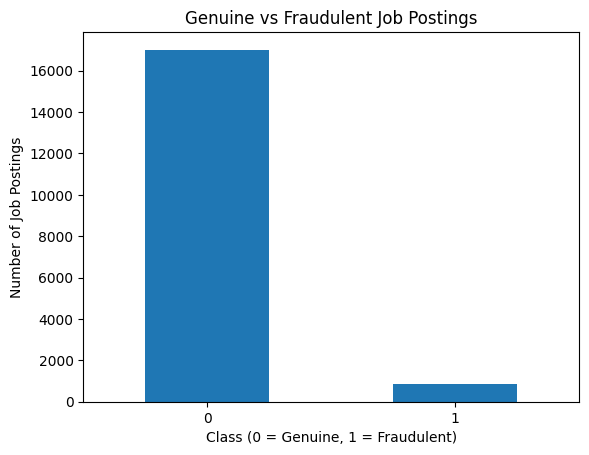

In [ ]:
if "fraudulent" in df.columns:
    counts = df["fraudulent"].value_counts().sort_index()

    counts.plot(kind="bar")

    plt.title("Genuine vs Fraudulent Job Postings")
    plt.xlabel("Class (0 = Genuine, 1 = Fraudulent)")
    plt.ylabel("Number of Job Postings")
    plt.xticks(rotation=0)
    plt.show()

In [ ]:
# Check important columns
required_columns = [
    "title",
    "company_profile",
    "description",
    "requirements",
    "employment_type",
    "fraudulent"
]

for column in required_columns:
    if column in df.columns:
        print(f"{column}: Available")
    else:
        print(f"{column}: Not available")

title: Available
company_profile: Available
description: Available
requirements: Available
employment_type: Available
fraudulent: Available


In [ ]:
# Select columns available in the dataset
available_columns = [
    column for column in required_columns
    if column in df.columns
]

df_clean = df[available_columns].copy()

print("Selected columns:", df_clean.columns.tolist())
print("Dataset shape:", df_clean.shape)

display(df_clean.head())

Selected columns: ['title', 'company_profile', 'description', 'requirements', 'employment_type', 'fraudulent']
Dataset shape: (17880, 6)


,title,company_profile,description,requirements,employment_type,fraudulent
0,Marketing Intern,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,Other,0
1,Customer Service - Cloud Video Production,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,Full-time,0
2,Commissioning Machinery Assistant (CMA),Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0
3,Account Executive - Washington DC,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Full-time,0
4,Bill Review Manager,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full-time,0


In [ ]:
# Fill missing text values
text_columns = [
    column for column in [
        "title",
        "company_profile",
        "description",
        "requirements",
        "employment_type"
    ]
    if column in df_clean.columns
]

for column in text_columns:
    df_clean[column] = df_clean[column].fillna("")

# Remove duplicate rows
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("Data cleaning completed!")
print("Cleaned dataset shape:", df_clean.shape)

display(df_clean.head())

Data cleaning completed!
Cleaned dataset shape: (16037, 6)


,title,company_profile,description,requirements,employment_type,fraudulent
0,Marketing Intern,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,Other,0
1,Customer Service - Cloud Video Production,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,Full-time,0
2,Commissioning Machinery Assistant (CMA),Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,,0
3,Account Executive - Washington DC,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Full-time,0
4,Bill Review Manager,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full-time,0


In [ ]:
# Combine available text columns
df_clean["job_text"] = ""

for column in text_columns:
    df_clean["job_text"] += (
        df_clean[column].astype(str) + " "
    )

# Remove rows with empty job text
df_clean = df_clean[
    df_clean["job_text"].str.strip().ne("")
].copy()

# Check target labels
df_clean["fraudulent"] = pd.to_numeric(
    df_clean["fraudulent"],
    errors="coerce"
)

df_clean = df_clean[
    df_clean["fraudulent"].isin([0, 1])
].copy()

df_clean["fraudulent"] = df_clean["fraudulent"].astype(int)

print("Text preparation completed!")
print("Total usable job postings:", len(df_clean))
print("\nTarget label counts:")
print(df_clean["fraudulent"].value_counts())

display(df_clean[["job_text", "fraudulent"]].head())

Text preparation completed!
Total usable job postings: 16037

Target label counts:
fraudulent
0    15319
1      718
Name: count, dtype: int64


,job_text,fraudulent
0,"Marketing Intern We're Food52, and we've creat...",0
1,Customer Service - Cloud Video Production 90 S...,0
2,Commissioning Machinery Assistant (CMA) Valor ...,0
3,Account Executive - Washington DC Our passion ...,0
4,Bill Review Manager SpotSource Solutions LLC i...,0


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Machine Learning libraries imported successfully!")

Machine Learning libraries imported successfully!


In [ ]:
# Input text
X = df_clean["job_text"]

# Target labels
y = df_clean["fraudulent"]

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("\nData splitting completed successfully!")

Training samples: 12829
Testing samples: 3208

Data splitting completed successfully!


In [ ]:
# Create TF-IDF vectorizer
tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2
)

# Learn text features from training data
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform test data using the same vocabulary
X_test_tfidf = tfidf.transform(X_test)

print("Text vectorization completed!")
print("Training feature shape:", X_train_tfidf.shape)
print("Testing feature shape:", X_test_tfidf.shape)

Text vectorization completed!
Training feature shape: (12829, 10000)
Testing feature shape: (3208, 10000)


In [ ]:
# Create the model
model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

# Train the model
model.fit(X_train_tfidf, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [ ]:
# Predict labels for test data
y_pred = model.predict(X_test_tfidf)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy:.2%}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Genuine Job", "Fraudulent Job"],
        zero_division=0
   )
)

Model Accuracy: 96.88%

Classification Report:
                precision    recall  f1-score   support

   Genuine Job       0.99      0.98      0.98      3064
Fraudulent Job       0.62      0.81      0.70       144

      accuracy                           0.97      3208
     macro avg       0.80      0.89      0.84      3208
  weighted avg       0.97      0.97      0.97      3208



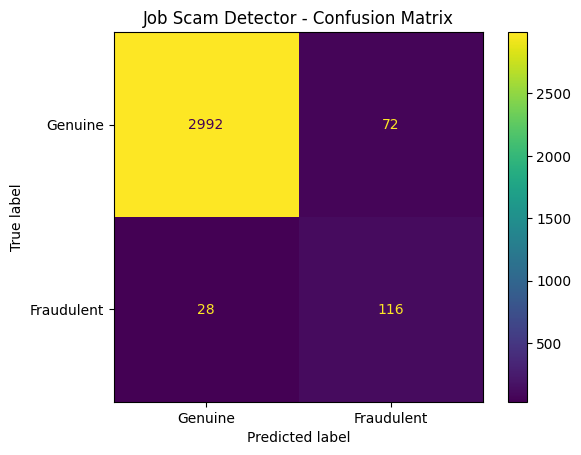

In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Genuine", "Fraudulent"]
)

display.plot()
plt.title("Job Scam Detector - Confusion Matrix")
plt.show()

In [ ]:
def predict_job_risk(job_description):
    # Convert input text using the trained TF-IDF vectorizer
    job_vector = tfidf.transform([job_description])

    # Predict the job posting class
    prediction = model.predict(job_vector)[0]

    # Get the model's estimated probability for each class
    probabilities = model.predict_proba(job_vector)[0]

    # Find the probability associated with the predicted class
    predicted_probability = probabilities[
        list(model.classes_).index(prediction)
    ]

    print("\n========== JOB RISK PREDICTION ==========")

    if prediction == 1:
        print("Prediction: Potentially Suspicious Job Posting")
    else:
        print("Prediction: Lower-Risk Job Posting")

    print(
        f"Model confidence estimate: "
        f"{predicted_probability:.2%}"
    )

    print("\nNote:")
    print("This is a machine learning prediction,")
    print("not proof that a job is genuine or fraudulent.")
    print("Always verify the company and job independently.")

    print("=========================================")

In [ ]:
sample_job = """
Job Title: Online Data Entry Assistant

Work from home opportunity.
No prior experience required.
Applicants must pay a registration fee
before receiving their appointment letter.
Company information is limited.
"""

predict_job_risk(sample_job)


========== JOB RISK PREDICTION ==========
Prediction: Potentially Suspicious Job Posting
Model confidence estimate: 96.52%

Note:
This is a machine learning prediction,
not proof that a job is genuine or fraudulent.
Always verify the company and job independently.


In [ ]:
sample_job_2 = """
Job Title: Junior Software Developer

We are looking for a junior software developer
with knowledge of Python and SQL.

Responsibilities include developing software,
testing applications, and working with the team.

Candidates can apply through the company's
official careers website.
"""

predict_job_risk(sample_job_2)


========== JOB RISK PREDICTION ==========
Prediction: Lower-Risk Job Posting
Model confidence estimate: 86.49%

Note:
This is a machine learning prediction,
not proof that a job is genuine or fraudulent.
Always verify the company and job independently.
